# Task 10 – Model Evaluation and Optimization

**Objective:** Evaluate the content-based, collaborative filtering and hybrid recommendation models, tune the hybrid weight, and select a final model configuration.

> **Note:** The user interaction data is **simulated** (created in Task 7). Results show how the methods behave on this small dataset and are not proof of real-world performance.


In [1]:
import pandas as pd                                          # tables
import numpy as np                                           # number helpers
import matplotlib.pyplot as plt                              # charts
from sklearn.feature_extraction.text import TfidfVectorizer  # text to numbers
from sklearn.metrics.pairwise import cosine_similarity       # similarity measure

In [2]:
# Step 1: load the Task 7 interaction data
interactions = pd.read_csv("../data/interaction/user_interactions.csv")
interactions["user_id"] = interactions["user_id"].astype(int)
interactions["talk_id"] = pd.to_numeric(interactions["talk_id"]).astype(int)

# Step 2: check the TED dataset has the columns we need
content_path = "../data/processed/ted_talks_cleaned.csv"
header = pd.read_csv(content_path, nrows=0).columns.tolist()
needed_cols = ["talk_id", "title", "description", "topics"]
missing_cols = [c for c in needed_cols if c not in header]

print("Interaction data shape:", interactions.shape)
print("Missing needed columns:", missing_cols)

if missing_cols:
    print("\n>>> Some columns are missing. Send me this output before going on.")
    print("Columns in cleaned TED file:", header)
else:
    talks = pd.read_csv(content_path, usecols=needed_cols)
    talks["talk_id"] = pd.to_numeric(talks["talk_id"])
    talks = talks.drop_duplicates(subset="talk_id").reset_index(drop=True)
    print("Talks loaded:", talks.shape)
    print("Interaction columns:", list(interactions.columns))

Interaction data shape: (181, 7)
Missing needed columns: []
Talks loaded: (4005, 4)
Interaction columns: ['user_id', 'talk_id', 'watched', 'rating', 'reaction', 'saved', 'data_source']


In [3]:
# --- Content model (same as Task 9: title + description + tags) ---
for col in ["title", "description", "topics"]:
    talks[col] = talks[col].fillna("")
talks["hybrid_text"] = talks["title"] + " " + talks["description"] + " " + talks["topics"]

tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(talks["hybrid_text"])      # text turned into numbers, built once
talk_index = pd.Series(talks.index, index=talks["talk_id"])   # talk_id -> row number
title_lookup = talks.set_index("talk_id")["title"]

# --- Evaluation catalogue ---
# Only the talks that appear in the interaction data can be judged, because for any other talk
# we do NOT know if the user would like it (unknown is not the same as irrelevant).
all_users = sorted(interactions["user_id"].unique())
catalogue = sorted(interactions["talk_id"].unique())
cat_pos = {t: i for i, t in enumerate(catalogue)}

# similarity between the catalogue talks, based on their text (24 x 24)
cat_sim = cosine_similarity(tfidf_matrix[talk_index[catalogue].values])

print("Users:", len(all_users), "| Catalogue talks:", len(catalogue))
print("Total interactions:", len(interactions))

Users: 24 | Catalogue talks: 24
Total interactions: 181


## How the models are evaluated

**Relevant talk** = a talk the user clearly liked (rating 4 or 5, or a "like" reaction).

**Held-out test:** for each user with at least 3 liked talks, I hide 2 of their liked talks (removed completely from the training data). Each model must then recommend 5 talks from the talks the user has not seen. A hidden talk that appears in the top 5 is a **hit**.

- **Precision@K** = hits ÷ K
- **Recall@K** = hits ÷ number of hidden talks (2)
- **Hit Rate@K** = share of users with at least one hit

**Reading the numbers:** with 2 hidden talks and K = 5, the best possible Precision@5 is 0.40 (2 ÷ 5) and the best possible Recall@5 is 1.00. A low-looking precision is therefore normal. Always compare against the **Random** baseline.

The whole test is repeated with **30 different random hidden sets**, so a lucky split can't decide the result. Models compared: Random, Popularity, Content-based, Collaborative, Hybrid.

In [4]:
def is_relevant(df):
    # liked = rating of 4 or more, or a "like" reaction
    return (df["rating"] >= 4) | (df["reaction"] == "like")

# liked talks per user
relevant_by_user = {int(u): sorted(set(g.loc[is_relevant(g), "talk_id"]))
                    for u, g in interactions.groupby("user_id")}

# only users with 3+ liked talks can be tested (2 hidden, at least 1 left to learn from)
eligible_users = [u for u, liked in relevant_by_user.items() if len(liked) >= 3]

def make_splits(n_splits=30, n_hidden=2, seed=42):
    # each split = (training data with hidden talks removed, {user: set of hidden talks})
    rng = np.random.default_rng(seed)
    splits = []
    for _ in range(n_splits):
        test = {u: {int(t) for t in rng.choice(relevant_by_user[u], size=n_hidden, replace=False)}
                for u in eligible_users}
        hidden_pairs = {(u, t) for u, talk_set in test.items() for t in talk_set}
        hide_mask = np.array([(int(u), int(t)) in hidden_pairs
                              for u, t in zip(interactions["user_id"], interactions["talk_id"])])
        splits.append((interactions[~hide_mask].copy(), test))
    return splits

splits = make_splits()
tune_splits = splits[:15]       # used to choose the best hybrid weight
confirm_splits = splits[15:]    # fresh splits used only to confirm the final choice

print("Eligible users for testing:", len(eligible_users), "of", len(all_users))
print("Number of splits:", len(splits), "(15 for tuning, 15 for confirming)")
print("Training rows in one split:", len(splits[0][0]), "of", len(interactions))

Eligible users for testing: 19 of 24
Number of splits: 30 (15 for tuning, 15 for confirming)
Training rows in one split: 143 of 181


In [5]:
def build_context(train, split_id=0):
    # everything the models need, built ONLY from the training data (so hidden talks can't leak)
    user_item = (train.pivot_table(index="user_id", columns="talk_id", values="rating", aggfunc="mean")
                      .reindex(index=all_users, columns=catalogue))
    similarity = pd.DataFrame(cosine_similarity(user_item.fillna(0)), index=all_users, columns=all_users)
    seen = {int(u): set(g.loc[(g["watched"] == 1) | g["rating"].notna(), "talk_id"])
            for u, g in train.groupby("user_id")}
    liked = {int(u): list(g.loc[is_relevant(g), "talk_id"].unique())
             for u, g in train.groupby("user_id")}
    popularity = (train[is_relevant(train)].groupby("talk_id")["user_id"].nunique()
                       .reindex(catalogue).fillna(0))
    return {"user_item": user_item, "sim": similarity, "seen": seen,
            "liked": liked, "popularity": popularity, "split_id": split_id}

def candidates_for(ctx, u):
    # talks the user has not seen yet
    return [t for t in catalogue if t not in ctx["seen"].get(u, set())]

def score_random(ctx, u):
    cand = candidates_for(ctx, u)
    rng = np.random.default_rng(ctx["split_id"] * 1000 + u)
    return pd.Series(rng.random(len(cand)), index=cand)

def score_popularity(ctx, u):
    # same list for everyone: talks liked by the most users
    return ctx["popularity"].loc[candidates_for(ctx, u)]

def score_content(ctx, u):
    # average text similarity to the talks this user liked
    cand = candidates_for(ctx, u)
    liked = ctx["liked"].get(u, [])
    if len(liked) == 0:
        return pd.Series(0.0, index=cand)                    # no history = no profile (cold start)
    liked_positions = [cat_pos[t] for t in liked]
    average_similarity = cat_sim[:, liked_positions].mean(axis=1)
    return pd.Series(average_similarity, index=catalogue).loc[cand]

def score_collaborative(ctx, u, n_neighbors=10):
    # predicted rating from the most similar users (same method as Task 8)
    cand = candidates_for(ctx, u)
    neighbors = ctx["sim"][u].drop(u).sort_values(ascending=False).head(n_neighbors)
    neighbors = neighbors[neighbors > 0]
    ratings = ctx["user_item"].loc[neighbors.index, cand]
    weighted_sum = ratings.fillna(0).mul(neighbors, axis=0).sum()
    similarity_sum = ratings.notna().mul(neighbors, axis=0).sum()
    return (weighted_sum / similarity_sum).fillna(0)         # nobody similar rated it = 0

def make_hybrid(cf_weight):
    # hybrid = cf_weight x collaborative (0 to 1) + (1 - cf_weight) x content (0 to 1)
    def score_hybrid(ctx, u):
        cf = score_collaborative(ctx, u) / 5.0
        content = score_content(ctx, u)
        content = content / content.max() if content.max() > 0 else content
        return cf_weight * cf + (1 - cf_weight) * content
    return score_hybrid

def make_hybrid_with_fallback(cf_weight):
    # hybrid for users with history, popular talks for brand-new users
    hybrid = make_hybrid(cf_weight)
    def score_hybrid_fallback(ctx, u):
        if len(ctx["liked"].get(u, [])) == 0:
            return score_popularity(ctx, u)
        return hybrid(ctx, u)
    return score_hybrid_fallback

models = {
    "Random": score_random,
    "Popularity": score_popularity,
    "Content-based": score_content,
    "Collaborative": score_collaborative,
    "Hybrid (0.5 / 0.5)": make_hybrid(0.5),
}
print("Models ready:", list(models.keys()))

Models ready: ['Random', 'Popularity', 'Content-based', 'Collaborative', 'Hybrid (0.5 / 0.5)']


In [6]:
def rank_talks(scores, seed=0):
    # shuffle first, then sort: talks with equal scores are ordered randomly, not by ID
    return scores.sample(frac=1, random_state=seed).sort_values(ascending=False, kind="stable").index

train0, test0 = splits[0]
ctx0 = build_context(train0, split_id=0)
example_user = list(test0.keys())[0]
hidden = test0[example_user]

print(f"Example user: {example_user}")
print("Hidden liked talks the models must find:")
for t in hidden:
    print("   -", t, title_lookup[t][:60])

for name, model_fn in models.items():
    top5 = list(rank_talks(model_fn(ctx0, example_user), seed=0)[:5])
    hits = [t for t in top5 if t in hidden]
    print(f"\n{name}:  hits = {len(hits)} | Precision@5 = {len(hits)/5:.2f} | Recall@5 = {len(hits)/len(hidden):.2f}")
    for t in top5:
        print("   ", t, title_lookup[t][:55], "  <-- HIT" if t in hidden else "")

Example user: 1
Hidden liked talks the models must find:
   - 2577 The agony of trying to unsubscribe
   - 206 Underwater astonishments

Random:  hits = 1 | Precision@5 = 0.20 | Recall@5 = 0.50
    206 Underwater astonishments   <-- HIT
    685 The thrilling potential of SixthSense technology 
    1386 Questions no one knows the answers to 
    2558 How trees talk to each other 
    2399 What makes a good life? Lessons from the longest study  

Popularity:  hits = 0 | Precision@5 = 0.00 | Recall@5 = 0.00
    263 What's wrong with what we eat 
    32560 The disarming case to act right now on climate change 
    66 Do schools kill creativity? 
    1386 Questions no one knows the answers to 
    1733 Grit: The power of passion and perseverance 

Content-based:  hits = 1 | Precision@5 = 0.20 | Recall@5 = 0.50
    2476 Your kids might live on Mars. Here's how they'll surviv 
    2577 The agony of trying to unsubscribe   <-- HIT
    2452 This country isn't just carbon neutral -- it's carbon 

In [7]:
def evaluate_models(models_dict, split_list, ks=(3, 5)):
    # run every model on every split and record Precision, Recall and Hit for each user
    rows = []
    for split_id, (train, test) in enumerate(split_list):
        ctx = build_context(train, split_id)
        for name, model_fn in models_dict.items():
            for u, hidden_set in test.items():
                ranked = rank_talks(model_fn(ctx, u), seed=split_id)
                for k in ks:
                    hits = len(set(ranked[:k]) & hidden_set)
                    rows.append({"split": split_id, "model": name, "user_id": u, "k": k,
                                 "precision": hits / k, "recall": hits / len(hidden_set),
                                 "hit": int(hits > 0)})
    return pd.DataFrame(rows)

def summarise(results, k):
    # average over users inside each split, then mean and spread across splits
    subset = results[results["k"] == k]
    per_split = subset.groupby(["model", "split"])[["precision", "recall", "hit"]].mean()
    table = per_split.groupby("model").agg(["mean", "std"])
    return pd.DataFrame({
        f"Precision@{k}": table[("precision", "mean")].round(3),
        f"Recall@{k}": table[("recall", "mean")].round(3),
        f"HitRate@{k}": table[("hit", "mean")].round(3),
        "Precision spread (std)": table[("precision", "std")].round(3),
    }).sort_values(f"Precision@{k}", ascending=False)

results_main = evaluate_models(models, splits, ks=(3, 5))

print("MODEL COMPARISON  (K = 5, averaged over 30 random splits)")
comparison_k5 = summarise(results_main, 5)
display(comparison_k5)

print("MODEL COMPARISON  (K = 3)")
display(summarise(results_main, 3))

MODEL COMPARISON  (K = 5, averaged over 30 random splits)


,Precision@5,Recall@5,HitRate@5,Precision spread (std)
model,,,,
Hybrid (0.5 / 0.5),0.260,0.650,0.905,0.029
Content-based,0.247,0.618,0.853,0.028
Collaborative,0.194,0.485,0.772,0.030
Random,0.111,0.278,0.493,0.029
Popularity,0.073,0.182,0.346,0.018


MODEL COMPARISON  (K = 3)


,Precision@3,Recall@3,HitRate@3,Precision spread (std)
model,,,,
Hybrid (0.5 / 0.5),0.333,0.500,0.795,0.052
Content-based,0.326,0.489,0.770,0.030
Collaborative,0.219,0.329,0.596,0.046
Random,0.111,0.166,0.312,0.039
Popularity,0.062,0.093,0.181,0.026


,cf_weight,Precision@5,Recall@5,HitRate@5,Precision spread (std)
0,0.0,0.239,0.598,0.853,0.027
1,0.1,0.238,0.595,0.860,0.026
2,0.2,0.250,0.625,0.874,0.023
3,0.3,0.251,0.626,0.867,0.024
4,0.4,0.258,0.644,0.888,0.031
5,0.5,0.254,0.635,0.902,0.034
6,0.6,0.239,0.596,0.874,0.033
7,0.7,0.228,0.570,0.839,0.029
8,0.8,0.214,0.535,0.814,0.031
9,0.9,0.201,0.502,0.779,0.033


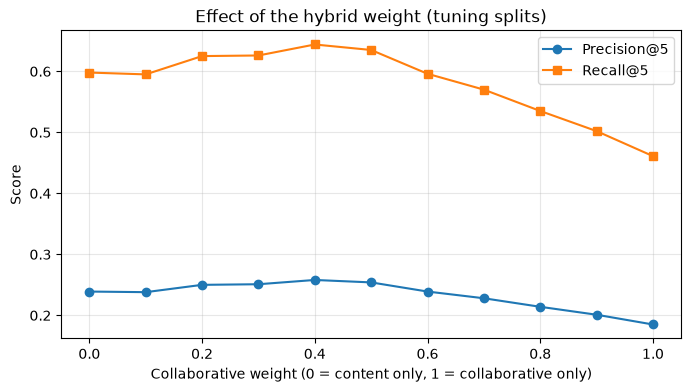

In [8]:
# cf_weight 0.0 = content only ... 1.0 = collaborative only. Tested on the TUNING splits only.
weights = [round(w, 1) for w in np.arange(0, 1.01, 0.1)]
weight_models = {f"w={w}": make_hybrid(w) for w in weights}
results_weights = evaluate_models(weight_models, tune_splits, ks=(3, 5))

weight_table = summarise(results_weights, 5)
weight_table["cf_weight"] = [float(name.split("=")[1]) for name in weight_table.index]
weight_table = weight_table.sort_values("cf_weight").reset_index(drop=True)
display(weight_table[["cf_weight", "Precision@5", "Recall@5", "HitRate@5", "Precision spread (std)"]])

# chart
plt.figure(figsize=(8, 4))
plt.plot(weight_table["cf_weight"], weight_table["Precision@5"], marker="o", label="Precision@5")
plt.plot(weight_table["cf_weight"], weight_table["Recall@5"], marker="s", label="Recall@5")
plt.xlabel("Collaborative weight (0 = content only, 1 = collaborative only)")
plt.ylabel("Score")
plt.title("Effect of the hybrid weight (tuning splits)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
# Pretend each eligible user is BRAND NEW: remove all their rows from training,
# then see if the models can still find their liked talks.
cold_splits = []
for u in eligible_users:
    train_without_user = interactions[interactions["user_id"] != u].copy()
    cold_splits.append((train_without_user, {u: set(relevant_by_user[u])}))

cold_models = {
    "Random": score_random,
    "Popularity": score_popularity,
    "Content-based": score_content,
    "Collaborative": score_collaborative,
    "Hybrid (0.5 / 0.5)": make_hybrid(0.5),
    "Hybrid + popularity fallback": make_hybrid_with_fallback(0.5),
}
results_cold = evaluate_models(cold_models, cold_splits, ks=(5,))

print("COLD-START RESULT (K = 5): brand-new users with no history")
display(summarise(results_cold, 5))
print("Compare each model with Random. Numbers here are NOT comparable to the earlier table,")
print("because here ALL of a user's liked talks are hidden, not just 2.")

COLD-START RESULT (K = 5): brand-new users with no history


,Precision@5,Recall@5,HitRate@5,Precision spread (std)
model,,,,
Collaborative,0.242,0.272,0.789,0.227
Content-based,0.242,0.272,0.789,0.227
Hybrid (0.5 / 0.5),0.242,0.272,0.789,0.227
Random,0.200,0.202,0.632,0.200
Hybrid + popularity fallback,0.147,0.178,0.684,0.112
Popularity,0.147,0.178,0.684,0.112


Compare each model with Random. Numbers here are NOT comparable to the earlier table,
because here ALL of a user's liked talks are hidden, not just 2.


In [10]:
# 1. pick the best weight on the TUNING splits (ties: higher Recall, then the more balanced weight)
weight_table["balance"] = (weight_table["cf_weight"] - 0.5).abs()
best_row = weight_table.sort_values(["Precision@5", "Recall@5", "balance"],
                                    ascending=[False, False, True]).iloc[0]
best_weight = float(best_row["cf_weight"])
print(f"Best collaborative weight on tuning splits: {best_weight}  (content weight = {round(1 - best_weight, 1)})")

# 2. confirm on FRESH splits against every other model
final_models = {
    "Random": score_random,
    "Popularity": score_popularity,
    "Content-based": score_content,
    "Collaborative": score_collaborative,
    f"Hybrid (cf_weight={best_weight})": make_hybrid(best_weight),
}
results_confirm = evaluate_models(final_models, confirm_splits, ks=(3, 5))

print("\nFINAL CONFIRMATION (K = 5, fresh splits)")
final_table_k5 = summarise(results_confirm, 5)
display(final_table_k5)
print("FINAL CONFIRMATION (K = 3)")
display(summarise(results_confirm, 3))

# 3. final configuration (what we would deploy)
FINAL_CONFIG = {
    "model": "Hybrid (content + collaborative)",
    "cf_weight": best_weight,
    "content_weight": round(1 - best_weight, 1),
    "k": 5,
    "text_features": "title + description + tags (Experiment 3, Task 6)",
    "neighbors": 10,
    "new_user_policy": "No model beat Random for brand-new users, so ask new users to pick topics or rate a few talks (onboarding) before using the hybrid",
}
print("\nFINAL CONFIGURATION:")
for key, value in FINAL_CONFIG.items():
    print(f"  {key}: {value}")

# 4. save the comparison tables
comparison_k5.to_csv("../reports/task_10_model_comparison.csv")
final_table_k5.to_csv("../reports/task_10_final_confirmation.csv")
print("\nTables saved in the reports folder.")

Best collaborative weight on tuning splits: 0.4  (content weight = 0.6)

FINAL CONFIRMATION (K = 5, fresh splits)


,Precision@5,Recall@5,HitRate@5,Precision spread (std)
model,,,,
Hybrid (cf_weight=0.4),0.272,0.679,0.916,0.019
Content-based,0.255,0.639,0.853,0.027
Collaborative,0.204,0.511,0.811,0.026
Random,0.111,0.277,0.488,0.024
Popularity,0.076,0.191,0.372,0.023


FINAL CONFIRMATION (K = 3)


,Precision@3,Recall@3,HitRate@3,Precision spread (std)
model,,,,
Hybrid (cf_weight=0.4),0.345,0.518,0.793,0.042
Content-based,0.327,0.491,0.765,0.028
Collaborative,0.226,0.339,0.618,0.046
Random,0.117,0.175,0.330,0.037
Popularity,0.067,0.100,0.200,0.026



FINAL CONFIGURATION:
  model: Hybrid (content + collaborative)
  cf_weight: 0.4
  content_weight: 0.6
  k: 5
  text_features: title + description + tags (Experiment 3, Task 6)
  neighbors: 10
  new_user_policy: No model beat Random for brand-new users, so ask new users to pick topics or rate a few talks (onboarding) before using the hybrid

Tables saved in the reports folder.


## Strengths and Weaknesses of Each Model

| Model | Strengths | Weaknesses |
|---|---|---|
| **Random** | Baseline to prove the other models add value | No intelligence |
| **Popularity** | Simple; needs no user history | Same list for everyone; in our test it did worse than Random, because the most popular talks are mostly ones users have already seen |
| **Content-based** | Uses talk text, so it can recommend talks nobody has rated; explainable ("similar topic"); needs only the user's own history | Needs at least one liked talk; keeps suggesting similar topics (over-specialisation); depends on text quality |
| **Collaborative** | Finds talks that don't read alike but similar users enjoyed (serendipity); learns from behaviour | Needs many users and ratings; fails for new users (cold start); only knows talks that someone rated; sparse data makes predictions weak |
| **Hybrid** | Combines both signals; weight can be tuned; more robust when one signal is weak | Needs tuning; more complex; one global weight for all users |

## Limitations

- **Small, simulated data:** 24 users and 24 talks with interactions, so results are indicative only.
- **Sparse interactions:** most user-talk pairs are empty, so collaborative predictions rely on few neighbours.
- **Cold start:** a new user has no history, so content and collaborative scores are empty and the models behave like random guessing. In my test even a popularity fallback did not beat Random. New users need onboarding (pick topics or rate a few talks) first.
- **Evaluation catalogue:** only the 24 talks with interaction data can be judged. Recommendations outside them cannot be evaluated, because unknown is not the same as irrelevant.
- **Offline metrics only:** Precision and Recall on hidden data do not measure real user satisfaction. An A/B test would be needed in a live system.

## Panel Questions and Answers

**1. How did you evaluate the models?**
I hid 2 liked talks per user, asked each model for 5 recommendations, and counted how many hidden talks it recovered. I repeated this with 30 random splits.

**2. What are Precision@K and Recall@K?**
Precision@K = hits ÷ K (how clean the list is). Recall@K = hits ÷ number of hidden talks (how many of the favourites were found).

**3. Why does Precision look low?**
With 2 hidden talks and K = 5, the maximum possible Precision@5 is 0.40. The right comparison is against the Random baseline, not against 1.0.

**4. Why include Random and Popularity?**
They show whether a smart model is actually adding value. If a model can't beat these simple ones, the extra complexity isn't justified.

**5. How did you pick the hybrid weight?**
I tested weights from 0 to 1 on 15 tuning splits, picked the best (0.4 collaborative, 0.6 content), and confirmed it on 15 fresh splits, so the weight wasn't just fitted to the same test.

**6. Is there data leakage?**
No. Hidden talks are removed completely from the training data, and the models are rebuilt from the training data for every split. The TF-IDF text features use no user labels.

**7. Why only 24 talks in the evaluation?**
Only those talks have interaction data. For other talks we don't know if a user would like them, and unknown is not the same as irrelevant.

**8. What about new users?**
This is the cold-start problem. In my cold-start experiment, no model did better than random guessing for a brand-new user: content and collaborative scores are empty, and the popularity fallback did even worse than Random on this data. So the sensible fix is onboarding: ask the new user to pick topics or rate 3 to 5 talks first, then use the hybrid.

**9. What are the limits of your result?**
The data is small and simulated, there are only 24 users, and offline metrics don't equal user satisfaction. On real data I would use more users, time-based splits and online A/B testing.

**10. How would you improve it in production?**
Use real interaction logs, matrix factorisation or implicit-feedback models, learn the weight per user, add diversity metrics, and retrain on a schedule.

**11. Why did Popularity score below Random?**
Popularity recommends the talks most users liked, but I only recommend talks the user has not seen. Those popular talks are mostly already seen, so what is left is less popular. This is a feature of the small simulated dataset.

## Final Model Selection

**Selected model:** Hybrid recommender, collaborative weight **0.4** + content weight **0.6**, top 5 recommendations, text features = title + description + tags (Task 6, Experiment 3), 10 neighbours.

**Evidence (fresh confirmation splits, K = 5):**

| Model | Precision@5 | Recall@5 | Hit Rate@5 |
|---|---|---|---|
| Hybrid (0.4 / 0.6) | 0.272 | 0.679 | 0.916 |
| Content-based | 0.255 | 0.639 | 0.853 |
| Collaborative | 0.204 | 0.511 | 0.811 |
| Random | 0.111 | 0.277 | 0.488 |
| Popularity | 0.076 | 0.191 | 0.372 |

**Why this model:**
1. **Best on every metric.** The hybrid ranked first on Precision, Recall and Hit Rate at both K = 3 and K = 5, in the 30-split comparison and again on fresh splits.
2. **Far better than guessing.** It finds about 2.4 times more hidden favourites than Random (Precision@5 0.272 vs 0.111). The maximum possible Precision@5 is 0.40, so it reaches about 68% of the ceiling.
3. **Clearly better than collaborative alone** (0.272 vs 0.204), because the collaborative model only has sparse ratings from 24 users.
4. **Slightly better than content alone** (0.272 vs 0.255). This edge is small compared with the spread between splits (about 0.02 to 0.03), so I do not claim a large improvement.
5. **Stable choice.** Precision between collaborative weights 0.2 and 0.6 stays between 0.250 and 0.258, so the exact weight is not fragile.
6. **Room to grow.** With more real users, the collaborative part should become stronger, while the content part keeps it working for talks nobody has rated yet.

**What it cannot do:** for a brand-new user with no history, no model beat random guessing, so new users need onboarding (pick topics or rate a few talks) first.

## Observations

*(All interaction data is simulated: 24 users, 24 talks, 181 interactions.)*

- **Every model beat the baselines for users with history.** Content-based, collaborative and hybrid all clearly beat Random, so the recommendations carry real signal.
- **Content-based beat collaborative** (Precision@5 0.247 vs 0.194 in the main comparison). Collaborative filtering has only a few ratings per user to find similar users from, while the text of a talk is always available.
- **The hybrid was best overall** (0.260 in the main comparison, 0.272 on fresh splits), because it uses both signals.
- **The weight curve rose from 0.0 to about 0.4 and then fell.** Precision@5 went from 0.239 (content only) up to 0.258 (weight 0.4) and down to 0.185 (collaborative only). Adding some collaborative signal to content helps, but too much hurts.
- **Popularity performed below Random** (0.073 vs 0.111). The most popular talks are mostly ones users have already seen, and seen talks are excluded.
- **Cold start:** for brand-new users, content, collaborative and hybrid have no scores and behave like random guessing, and the popularity fallback was not better than Random. The practical fix is onboarding.
- **Limitations:** small simulated data, only 24 talks can be evaluated, very sparse interactions, results vary by about 0.02 to 0.03 between splits, and offline metrics do not measure real user satisfaction.